# Домашнее задание по теме «Метрические алгоритмы»



Для большинства алгоритмов классического машинного обучения давно существуют готовые реализации: мы уже использовали kNN из sklearn в семинарах. Это очень удобно для решения практических задач, потому что для получения результата достаточно нескольких строк кода. Но чтобы эффективно использовать такие модели, важно понимать их ограничения, сильные и слабые стороны — то, как они работают «под капотом».

В этом домашнем задании ты узнаешь детали реализации метрических алгоритмов:
- kNN (обычный, взвешенный, для задачи классификации, для задачи регрессии);
- регрессии Надарая — Ватсона.

Написав эти модели с нуля, ты:
- поймёшь, как работает логика поиска соседей, взвешивания;
- разберёшься, как изменение параметров влияет на результат;
- научишься работать с ошибками и отлаживать модели в будущем.

Что нужно будет сделать:
- реализовать `BaseKNN` — класс с основными методами, фундамент для остальных моделей kNN;
- построить модели, решающие задачу регрессии (`KNNRegressor`) и классификации (`KNNClassifier`) на основе `BaseKNN`;
- познакомиться с обобщением взвешенной регрессии — `NadarayaWatsonRegressor`;
- сравнить результаты построенных моделей с аналогичными из sklearn.

Как понять, что задание выполнено хорошо:

- все `# Напиши код здесь` заполнены, и код работает без ошибок;
- результаты твоих реализаций KNNClassifier и KNNRegressor сопоставлены с результатами sklearn. Небольшие численные различия и различия при равенстве голосов допустимы.
- даны чёткие, развёрнутые ответы на вопросы.

## Подготовка

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,
    mean_squared_error, r2_score
)

In [2]:
def get_train_test(complex_function:callable, num_points=100, outliers=False, **kwargs):
    """ Генерация данных """
    np.random.seed(123)

    X = np.linspace(0, 10, num_points)
    X = X.reshape(-1, 1)

    X_train = X[::3] # Берём каждый третий элемент для обучения
    X_test = X[np.setdiff1d(np.arange(len(X)), np.arange(0, len(X), 3))] # Оставшиеся — для теста
    # Тут мы могли бы сгенерировать новый х: например, более плотно распределённые точки
    # Главное — что есть некоторые точки исходной функции, между которыми нужно заполнить пустое пространство

    # Значения функции с шумом
    y_train = complex_function(X_train).ravel() + np.random.normal(0, 0.2, len(X_train))
    y_test = complex_function(X_test).ravel() + np.random.normal(0, 0.2, len(X_test))

    if outliers:
        y_train = add_outliers(y_train, **kwargs)

    return X, X_train, X_test, y_train, y_test

def add_outliers(y,
                 num_outliers=None,
                 strength_std_devs=None,
                 random_seed=42):
    """ Добавление выбросов """

    if not num_outliers:
        num_outliers = int(len(y_train) * 0.1)

        if num_outliers == 0:
            num_outliers = 2

    if not strength_std_devs:
        strength_std_devs = 5

    y = np.array(y)
    y_with_outliers = y.copy()

    std_dev = np.std(y)

    if std_dev == 0:
        outlier_shift = strength_std_devs
    else:
        outlier_shift = strength_std_devs * std_dev

    rng = np.random.RandomState(seed=random_seed)

    # Случайно выбираем индексы выбросов
    outlier_indices = rng.choice(len(y), num_outliers, replace=False)

    for idx in outlier_indices:
        # Произвольно решаем, будет ли outlier больше или меньше текущего значения
        sign = rng.choice([-1, 1])
        y_with_outliers[idx] += sign * outlier_shift * (rng.rand() * 0.5 + 0.5)

    return y_with_outliers

def plot_data(X, X_train, X_test, y_train, y_test,
              complex_function:callable,
              pred=None,
              labels=[''],
              title='Синтетические данные для регрессии',
              subplot=None,
              highlight_train_range=None):
    """ Визуализация данных/результатов"""

    if not subplot:
        plt.figure(figsize=(12, 6))

    plt.scatter(X_train, y_train, c='black', alpha=0.5, label='Обучающая выборка')
    plt.scatter(X_test, y_test, c='gray', alpha=0.5, label='Тестовая выборка')
    plt.plot(X, complex_function(X), 'b-', label='Истинная функция')

    if pred is not None:
        for y_pred, label in zip(pred, labels):
            plt.plot(X_test, y_pred, alpha=1, label=label)

    if highlight_train_range:
        plt.axvspan(highlight_train_range[0], highlight_train_range[1],
                     color='lightgray', alpha=0.4, zorder=-1, label='Диапазон обучения')

    plt.grid(True)
    plt.legend()
    plt.title(title)

## Реализация собственного kNN

### Задача 1. Реализация BaseKNN [2,5 балла]

Класс ```BaseKNN``` — основа всех моделей. Его задачи:
* хранение обучающей выборки;
* реализация логики ключевого функционала kNN — поиска ближайших соседей (метод ```_find_k_nearest_neighbours```);
* вычисление весов на основе расстояний (метод ```_calculate_weights```).

Ниже представлен код с базовой структурой классов. Твоя задача — заполнить пропущенные части, руководствуясь комментариями и описаниями.

#### Задача 1.1. Функции ядра [0,5 балла]

Реализуй следующие функции ядра:

1. Гауссово — `_gaussian_kernel`:
$$\frac{1}{\sqrt{2\pi}}\exp(-\frac{1}{2}d^2).$$
2. Епанечникова — `_epanechnikov_kernel`:
$$\frac{3}{4}(1-d^2)\cdot I(|d|\le1).$$
3. Треугольное — `_triangular_kernel`:
$$(1-|d|)\cdot I(|d|\le1).$$
4. Прямоугольное — `_uniform_kernel`:
$$\frac{1}{2}I(|d|\le1).$$

#### Задача 1.2. Метод ```fit``` [0,5 балла]

1. Преобразуй $X$ и $Y$ в `np.array` с помощью функции `ensure_numpy`.
2. Убедись, что $X$ — двумерный массив (`n_points`, `n_features`).
3. Если $X$ одномерный (`n_points`), преобразуй его в (`n_samples`, 1): это необходимо для корректного вычисления расстояний.

#### Задача 1.3. Метод ```_find_k_nearest_neighbours``` [0,75 балла]

1. Вычисли расстояния от $x$ до всех точек в `self.X_train`, используя `np.linalg.norm (..., $axis=1$)`.
2. Найди индексы ближайших соседей, используя `np.argsort()`.
3. Найди расстояния до этих ближайших соседей.

#### Задача 1.4. Метод ```_calculate_weights``` [0,75 балла]

Примени взвешивание `inverse distance` для `weights == 'distance'`:
$$\frac{1}{\left|d\right|+\epsilon}.$$

В ином случае:
1. Масштабируй расстояния на `self.bandwidth` и `self.epsilon`.
2. Примени выбранную функцию ядра `self._weighting_function`.

> **Примечание.** Здесь $d$ — distances (`np.array`).

In [3]:
from collections import defaultdict, Counter
import logging

def ensure_numpy(data):
    """ Функция для проверки типа входных данных """
    if isinstance(data, pd.DataFrame) or isinstance(data, pd.Series):
        return data.values
    return np.asarray(data)

class BaseKNN():
    def __init__(self, n_neighbours=5, weights='uniform', kernel='uniform', bandwidth=1.0, epsilon=1e-6):
        """ Базовый класс, который отвечает за запоминание выборки и поиск ближайших соседей """
        self.n_neighbours = n_neighbours
        self.weights = weights
        self.kernel = kernel
        self.bandwidth = bandwidth
        self.epsilon = epsilon
        self.X_train = None
        self.y_train = None

        self._weighting_function = self._get_kernel_function(self.kernel)

    def _gaussian_kernel(self, d):
        return (1.0 / np.sqrt(2 * np.pi)) * np.exp(-0.5 * d**2)

    def _epanechnikov_kernel(self, d):
        return 0.75 * (1.0 - d**2) * (np.abs(d) <= 1.0)

    def _triangular_kernel(self, d):
        return (1.0 - np.abs(d)) * (np.abs(d) <= 1.0)

    def _uniform_kernel(self, d):
        return 0.5 * (np.abs(d) <= 1.0)

    def _get_kernel_function(self, kernel_name):
        """
        Возвращает функцию ядра в зависимости от выбранного типа
        """
        kernels = {
            'gaussian': self._gaussian_kernel,
            'epanechnikov': self._epanechnikov_kernel,
            'triangular': self._triangular_kernel,
            'uniform': self._uniform_kernel
        }

        return kernels.get(kernel_name)

    def fit(self, X, y):
        """
        Обучение kNN. Фактически - запоминание данных из обучающей выборки
        """
        self.X_train = ensure_numpy(X)
        self.y_train = ensure_numpy(y)

        if self.X_train.ndim == 1:
            self.X_train = self.X_train.reshape(-1, 1)

        return self

    def _find_k_nearest_neighbours(self, x):
        """
        Поиск k ближайших соседей для одной точки

        :param x: одна точка из тестовой выборки, shape (n_features)

        :return k_indices: индексы ближайших соседей из обучающей выборки
        :return k_distances: расстояния до каждого из k ближайших соседей
        """
        # Напиши код здесь: реализуй поиск k ближайших соседей
        distances = np.linalg.norm(self.X_train - x, axis=1)
        k_indices = np.argsort(distances)[:self.n_neighbours]
        k_distances = distances[k_indices]
        return k_indices, k_distances


    def _calculate_weights(self, distances):
        """
        Подсчёт весов для одной точки. Масштабируем расстояния, используя
        параметр bandwidth, затем передаём их в функцию ядра.

        :param distances: массив расстояний от тестовой точки до других точек (n_features)

        :return: массив расстояний с применением функции ядра (n_features)
        """
        if self.weights == 'distance':
            weights = 1.0 / (np.abs(distances) + self.epsilon)
            return weights

        scaled_distances = distances / (self.bandwidth + self.epsilon)
        weighted_distances = self._weighting_function(scaled_distances)
        return weighted_distances


    def predict(self, X):
        """ Реализуем этот метод в дочерних классах """
        raise NotImplementedError("Не реализован в базовом kNN")


Основа готова. В ней реализован весь базовый функционал, необходимый kNN для решения любой задачи.

### Задача 2. KNNRegressor [2 балла]

Займёмся регрессией. Идея в следующем: предсказание новой точки — это среднее (или взвешенное среднее) значений её соседей.

Нужно:
 * реализовать обычный регрессор (```if self.weights == 'uniform':```),
 * протестировать его,
 * перейти к взвешенному.

> **Примечание.** Далее все указания будут приведены в комментариях.

#### Задача 2.1. Метод ```predict``` [1,25 балла]

Реализуй метод ```predict``` для регрессора.

#### Задача 2.2. Метод ```predict``` (взвешивание) [0,75 балла]

Реализуй взвешивание в методе  ```predict```: `if self.weights != 'uniform'`.

In [4]:
class KNNRegressor(BaseKNN):
    def __init__(self, n_neighbours=5, weights='uniform', kernel='uniform', bandwidth=1.0, epsilon=1e-6):
        super().__init__(n_neighbours=n_neighbours,
                         weights=weights,
                         kernel=kernel,
                         bandwidth=bandwidth,
                         epsilon=epsilon)

    def predict(self, X):
        """
        Предсказывает значения для тестовой выборки X

        :param X: тестовые данные (n_test_points, n_features)

        :return y_pred: массив предсказанных для каждой точки значений (n_test_points)
        """
        # Преобразуй X в numpy.array по аналогии с методом .fit()
        # Убедись, что X — двумерный массив

        X = ensure_numpy(X)
        if X.ndim == 1:
            X = X.reshape(-1, 1)

        # Инициализируй массив для предсказаний (n_test_points)
        # Значения в нём будут обновляться итеративно
        y_pred = np.zeros(X.shape[0])

        for i, x in enumerate(X):
            k_indices, k_distances = self._find_k_nearest_neighbours(x)
            k_targets = self.y_train[k_indices]

            if self.weights == 'uniform':
                # Это обычный kNN. Предсказание — среднее значение k_targets
                # Напиши код здесь
                y_pred[i] = np.mean(k_targets)
            else:
                # Взвешенный kNN. Предсказание — взвешенное среднее k_targets
                # Напиши код здесь
                k_weights = self._calculate_weights(k_distances)
                weights_sum = np.sum(k_weights)

                if weights_sum == 0:
                    y_pred[i] = np.mean(k_targets)
                else:
                    y_pred[i] = np.sum(k_weights * k_targets) / weights_sum


        return y_pred



Отлично! Теперь попробуй протестировать свою модель. Сравни предсказания и метрики со sklearn. Небольшие численные различия допустимы.

In [5]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target, name='target')


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn_reg = KNNRegressor(n_neighbours=5)
knn_reg_Sklearn = KNeighborsRegressor(n_neighbors=5)

knn_reg.fit(X_train_scaled, y_train)
knn_reg_Sklearn.fit(X_train_scaled, y_train)

y_pred_reg = knn_reg.predict(X_test_scaled)
y_pred_reg_Sklearn = knn_reg_Sklearn.predict(X_test_scaled)

print(f"Наша реализация R2 Score: {r2_score(y_test, y_pred_reg):.3f}, MSE: {mean_squared_error(y_test, y_pred_reg):.3f}")
print(f"Sklearn R2 Score: {r2_score(y_test, y_pred_reg_Sklearn):.3f}, MSE: {mean_squared_error(y_test, y_pred_reg_Sklearn):.3f}")

Наша реализация R2 Score: 0.670, MSE: 0.432
Sklearn R2 Score: 0.670, MSE: 0.432


In [6]:
same = 0
different = 0
for i, j in zip(y_pred_reg, y_pred_reg_Sklearn):
    if i == j:
        same += 1
    else:
        different += 1
        print('different')

print(f'Совпадений: {same}')
print(f'Различий: {different}')

Совпадений: 4128
Различий: 0


Теперь взвешивания.

In [7]:
knn_reg = KNNRegressor(n_neighbours=5, weights='distance')
knn_reg_Sklearn = KNeighborsRegressor(n_neighbors=5, weights='distance')

knn_reg.fit(X_train_scaled, y_train)
knn_reg_Sklearn.fit(X_train_scaled, y_train)

y_pred_reg = knn_reg.predict(X_test_scaled)
y_pred_reg_Sklearn = knn_reg_Sklearn.predict(X_test_scaled)

print(f"Наша реализация R2 Score: {r2_score(y_test, y_pred_reg):.3f}, MSE: {mean_squared_error(y_test, y_pred_reg):.3f}")
print(f"Sklearn R2 Score: {r2_score(y_test, y_pred_reg_Sklearn):.3f}, MSE: {mean_squared_error(y_test, y_pred_reg_Sklearn):.3f}")

Наша реализация R2 Score: 0.672, MSE: 0.430
Sklearn R2 Score: 0.672, MSE: 0.430


После сравнения результатов со sklearn переходи к классификации.

### Задача 3. KNNClassifier [5,5 балла]

Действовать будем аналогично регрессору, но вместо усреднения значений обратимся к голосованию. Предскажем тот класс, который встречается чаще других среди соседей.

Нужно:
* реализовать обычный классификатор (```if self.weights == 'uniform':```),
* протестировать его,
* перейти к взвешенному.

#### Задача 3.1. Метод ```fit``` [0,5 балла]

Дополни метод ```fit``` для классификатора. Кроме вызова родительского ```fit``` нужно сохранить уникальные классы и их количество в атрибуты класса.

#### Задача 3.2. Метод ```predict``` [2 балла]

Реализуй метод ```predict``` для классификатора, следуя указаниям в комментариях.

#### Задача 3.3. Метод ```predict``` (взвешивание) [0,75 балла]
Реализуй взвешивание в методе  ```predict```: `if self.weights != 'uniform':...`.

#### Задача 3.4. Метод ```predict_proba``` [1,5 балла]
Реализуй метод ```predict_proba``` для классификатора, следуя указаниям в комментариях.

#### Задача 3.5. Метод ```predict_proba``` (взвешивание) [0,75 балла]

Реализуй взвешивание в методе  ```predict_proba```: `if self.weights != 'uniform':...`.

In [8]:
class KNNClassifier(BaseKNN):
    def __init__(self, n_neighbours=5, weights='uniform', kernel='uniform', bandwidth=1.0, epsilon=1e-6):
        super().__init__(n_neighbours=n_neighbours,
                         weights=weights,
                         kernel=kernel,
                         bandwidth=bandwidth,
                         epsilon=epsilon)

        self.classes_ = None
        self.n_classes_ = 0


    def fit(self, X, y):
        super().fit(X, y)
        # Для метода predict_proba понадобятся уникальные метки классов и их количество
        self.classes_ = np.unique(self.y_train)
        self.n_classes_ = len(self.classes_)
        return self


    def predict(self, X):
        """
        Предсказание меток классов для тестовой выборки X.

        Для каждой точки ищется k ближайших соседей из обучающей выборки.
        Предсказанной меткой класса становится метка, наиболее часто встречающаяся
        среди k соседей — majority vote

        При равенстве голосов или сумм весов выбирается первый класс из candidates

        :param X: тестовые данные (n_test_points, n_features)

        :return y_pred: массив предсказанных для каждой точки меток классов (n_test_points)
        """
        # Преобразуй X в numpy.array по аналогии с методом .fit()
        # Убедись, что X — двумерный массив

        X = ensure_numpy(X)
        if X.ndim == 1:
            X = X.reshape(-1, 1)

        # Инициализируй массив для предсказаний (n_test_points)
        # Значения в нём будут обновляться итеративно
        y_pred = np.zeros(X.shape[0], dtype=self.y_train.dtype)

        for i, x in enumerate(X):
            k_indices, k_distances = self._find_k_nearest_neighbours(x)
            k_labels = self.y_train[k_indices]

            if self.weights == 'uniform':
                # Посчитай, сколько раз встречается каждая метка среди k_labels
                # hint: используй collections.Counter()
                label_counts = Counter(k_labels)
            else:
                calculated_weights = self._calculate_weights(k_distances)
                label_weights_sum = defaultdict(float)
                """
                Словарь label_weights_sum хранит сумму весов каждой метки класса,
                встретившейся среди k соседей
                По сути, defaultdict — это тот же dict, но при обращении
                к несуществующему ключу этот ключ инициализируется в словаре
                с некоторым default значением (в нашем случае 0.0)
                """

                # Напиши код здесь: для каждой метки из k_labels просуммируй её веса
                for lbl, w in zip(k_labels, calculated_weights):
                    label_weights_sum[lbl] += w

                label_counts = label_weights_sum

            """
            label_counts — это словарь, который помогает
            удобно считать количество повторений каждого ключа:
            Counter({label1: frequency1, label2: frequency2,..., label_k: frequency_k})
            """

            # Найди самую частую метку
            # hint: используй most_common()
            if isinstance(label_counts, Counter):
                most_frequent_labels = label_counts.most_common()
            else:
                most_frequent_labels = sorted(label_counts.items(), key=lambda item: item[1], reverse=True)

            """
            most_frequent_labels выглядит так:
            ((label1, frequency1), (label2, frequency2),..., (label_k, frequency_k))
            Этот массив отсортирован по убыванию частот (второго элемента каждого кортежа)
            К такой коллекции можно обращаться по индексам:
            most_frequent_labels[0] вернёт label1: frequency1
            most_frequent_labels[0][0] вернёт label1
            most_frequent_labels[0][1] вернёт frequency1
            """

            max_frequency = most_frequent_labels[0][1]
            candidates = [label for label, freq in most_frequent_labels if freq == max_frequency]

            if len(candidates) > 1:
                logging.info(f"Точка с индексом {i} имеет несколько вариантов "
                f"определения класса: {len(candidates)} классов встречаются "
                f"{max_frequency} раз в окрестности. Выбран первый класс из candidates.")


            y_pred[i] = candidates[0]


        return y_pred

    def predict_proba(self, X):
        """
        Оценка вероятности принадлежности каждой точки из тестовых данных к каждому классу

        Для каждой точки ищется k ближайших соседей из обучающей выборки.
        Вероятность принадлежности к классу определяется как отношение частот
        наблюдения меток класса в окрестности к количеству ближайших соседей k


        :param X: тестовые данные (n_test_points, n_features)

        :return probas: массив предсказанных для каждой точки меток классов (n_test_points, n_features),
                        где probas[i, j] представляет собой вероятность принадлежности
                        объекта i к классу j.
         """
        # Преобразуй X в numpy.array по аналогии с методом .fit()
        # Убедись, что X — двумерный массив

        X = ensure_numpy(X)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        n_test_points = X.shape[0]

        classes = self.classes_
        n_classes = self.n_classes_

        probas = np.zeros((n_test_points, n_classes))
        class_to_idx = {cls: idx for idx, cls in enumerate(classes)}

        for i, x in enumerate(X):
            k_indices, k_distances = self._find_k_nearest_neighbours(x)
            k_labels = self.y_train[k_indices]


            if self.weights == 'uniform':
                label_counts = Counter(k_labels)

                # Для каждого класса из classes
                # P = (число соседей этого класса) / (k)

                # Напиши код здесь: итерируя по ключам j из label_counts, обнови probas[i, j]
                for lbl, count in label_counts.items():
                  if lbl in class_to_idx:
                    j = class_to_idx[lbl]
                    probas[i, j] = count / self.n_neighbours

            else:
                calculated_weights = self._calculate_weights(k_distances)
                weights_sum = np.sum(calculated_weights)

                if weights_sum == 0:
                    label_counts = Counter(k_labels)
                    for lbl, count in label_counts.items():
                        if lbl in class_to_idx:
                            j = class_to_idx[lbl]
                            probas[i, j] = count / self.n_neighbours
                else:
                    label_weights_sum = defaultdict(float)
                    for lbl, w in zip(k_labels, calculated_weights):
                        label_weights_sum[lbl] += w

                    for lbl, w_sum in label_weights_sum.items():
                        if lbl in class_to_idx:
                            j = class_to_idx[lbl]
                            probas[i, j] = w_sum / weights_sum

                # Напиши код здесь: найди сумму весов каждой встречающейся среди n_neighbours метки класса

                # Для каждого класса из classes
                # P = (сумма весов соседей этого класса) / (сумма весов всех k соседей)

                # Напиши код здесь: обнови вероятности в probas

        return probas


Протестируй модель и сравни результаты со sklearn. При равенстве голосов предсказанные классы могут различаться из-за разных правил выбора.

In [9]:
from sklearn.datasets import load_digits
from sklearn.metrics import log_loss

data = load_digits()

X = pd.DataFrame(data.data, columns=data.feature_names)
X = X.to_numpy()
y = pd.Series(data.target, name='target')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

my_knn = KNNClassifier(n_neighbours=5, weights='uniform')
Sklearn_knn = KNeighborsClassifier(n_neighbors=5, weights='uniform')

my_knn.fit(X_train_scaled, y_train)
Sklearn_knn.fit(X_train_scaled, y_train)

y_pred = my_knn.predict(X_test_scaled)
y_pred_Sklearn = Sklearn_knn.predict(X_test_scaled)

print('Наша реализация accuracy:', accuracy_score(y_test, y_pred))
print('Sklearn accuracy:', accuracy_score(y_test, y_pred_Sklearn))

diffs = np.where(y_pred != y_pred_Sklearn)[0]
print(f"\nРазличия в предсказаниях: {len(diffs)} точек")

y_proba = my_knn.predict_proba(X_test_scaled)
y_proba_Sklearn = Sklearn_knn.predict_proba(X_test_scaled)

print(f'Наша реализация predict_proba log loss: {log_loss(y_test, y_proba):.4f}')
print(f'Sklearn predict_proba log loss: {log_loss(y_test, y_proba_Sklearn):.4f}')

Наша реализация accuracy: 0.975
Sklearn accuracy: 0.975

Различия в предсказаниях: 0 точек
Наша реализация predict_proba log loss: 0.1584
Sklearn predict_proba log loss: 0.1584


Протестируй взвешенный kNN.

In [10]:
my_knn_weighted = KNNClassifier(n_neighbours=5, weights='distance')
Sklearn_knn_weighted = KNeighborsClassifier(n_neighbors=5, weights='distance')

my_knn_weighted.fit(X_train_scaled, y_train)
Sklearn_knn_weighted.fit(X_train_scaled, y_train)

y_pred_weighted = my_knn_weighted.predict(X_test_scaled)
y_pred_Sklearn_weighted = Sklearn_knn_weighted.predict(X_test_scaled)

print('Взвешенная наша accuracy:', accuracy_score(y_test, y_pred_weighted))
print('Взвешенная sklearn accuracy:', accuracy_score(y_test, y_pred_Sklearn_weighted))

diffs = np.where(y_pred_weighted != y_pred_Sklearn_weighted)[0]
print(f"\nРазличия в предсказаниях: {len(diffs)} точек")

Взвешенная наша accuracy: 0.975
Взвешенная sklearn accuracy: 0.975

Различия в предсказаниях: 0 точек


Последний рывок: регрессия Надарая — Ватсона.

### Задача 4. NadarayaWatsonRegressor [1 балл]

В рамках семинара поговорить о данном алгоритме мы не успели, но можно прочитать о нем в [лонгриде](https://centraluniversity.yonote.ru/share/722d267c-f3b8-47f4-b9cb-ff4e51edd3ff/doc/metricheskie-algoritmy-ZMYQFiQ6CZ#h-regressiya-nadaraya-%E2%80%94-vatsona) недели. В задании ниже предлагается реализовать метод ```predict``` для регрессии Надарая — Ватсона.

In [12]:
class NadarayaWatsonRegressor(BaseKNN):
    def __init__(self, kernel='uniform', bandwidth=1.0, epsilon=1e-6):
        super().__init__(weights='kernel',
                         kernel=kernel,
                         bandwidth=bandwidth,
                         epsilon=epsilon)

    def predict(self, X):

        # Преобразуй X в numpy.array по аналогии с методом .fit()
        # Убедись, что X — двумерный массив

        X = ensure_numpy(X)
        if X.ndim == 1:
          X = X.reshape(-1, 1)

        y_pred = np.zeros(X.shape[0])

        for i, x in enumerate(X):
          distances = np.linalg.norm(self.X_train - x, axis=1)
          weights = self._calculate_weights(distances)
          weights_sum = np.sum(weights)

          if weights_sum == 0:
            y_pred[i] = np.mean(self.y_train)
          else:
            y_pred[i] = np.sum(weights * self.y_train) / weights_sum

        return y_pred


Попробуй сгенерировать более сложную функцию.

In [13]:
def complex_function(x):
    """ Сложная функция: комбинация синусоиды, полинома и экспоненты """
    return (np.sin(x) +
            0.5 * np.sin(2 * x) +
            0.1 * (x - 5) ** 2 +
            0.05 * np.exp(x / 5))

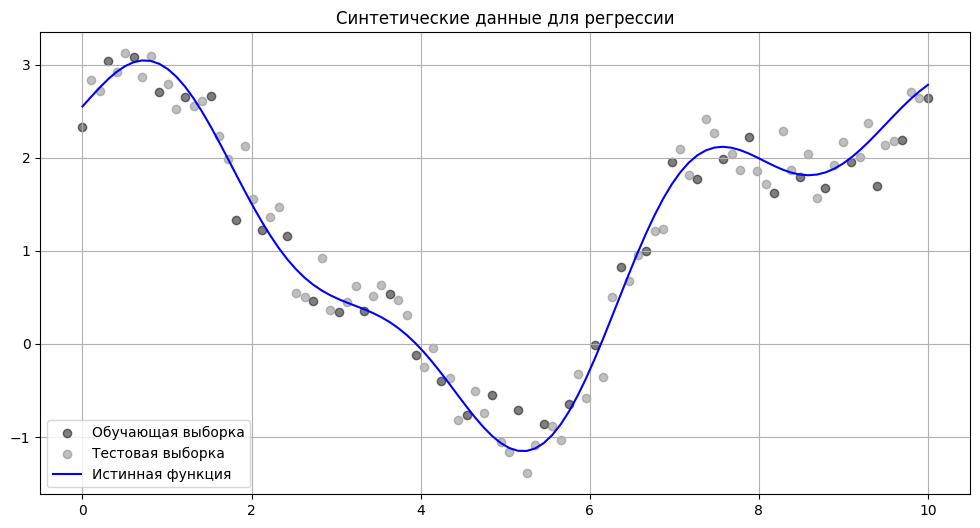

In [14]:
X, X_train, X_test, y_train, y_test = get_train_test(complex_function, num_points=100)
plot_data(X, X_train, X_test, y_train, y_test, complex_function)

Посмотрим, что меняется при применении разных ядерных функций и использовании разной ширины окна.

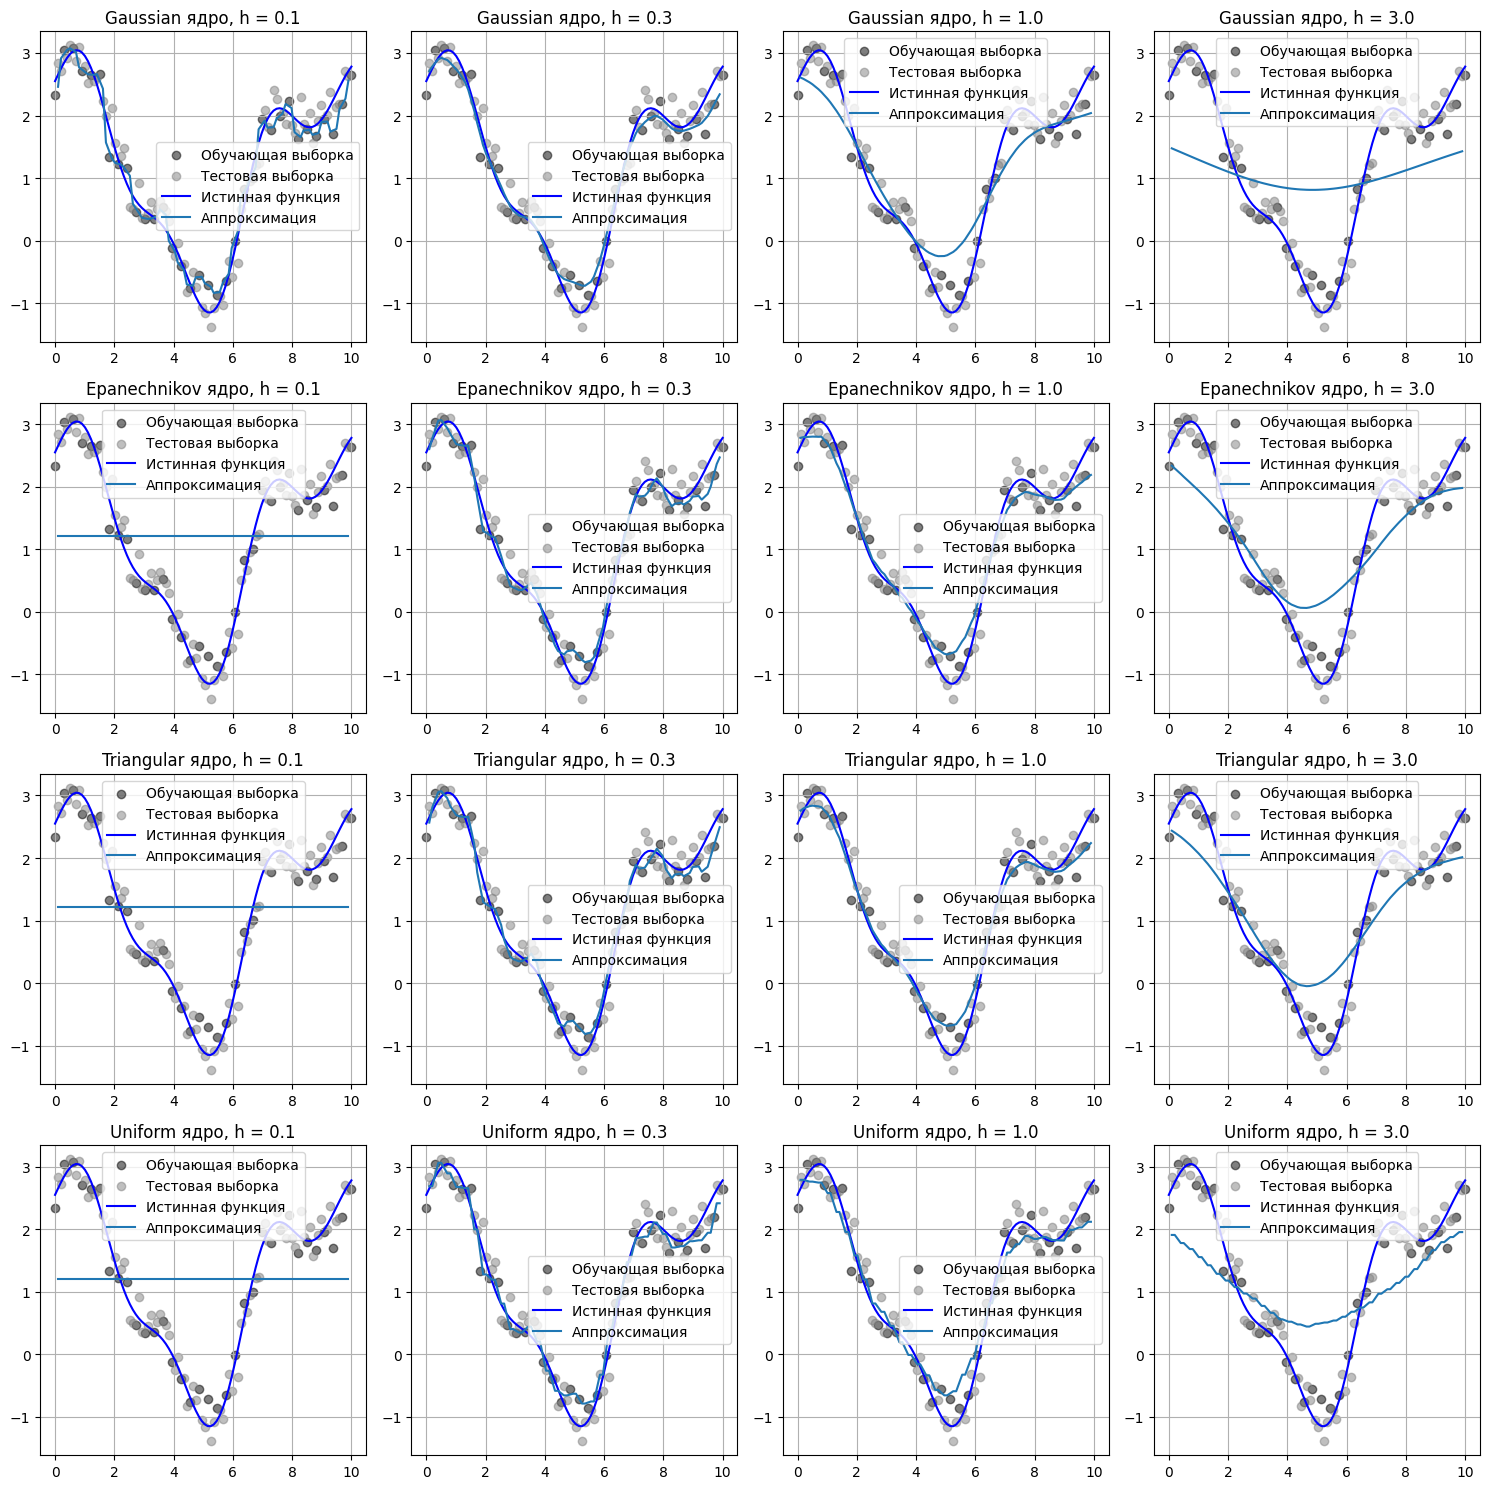

In [15]:
kernels = ['gaussian', 'epanechnikov', 'triangular', 'uniform'] # Сравни разные ядра
bandwidths = [0.1, 0.3, 1.0, 3.0] # Сравни разные размеры окна

plt.figure(figsize=(15, 15))
plot_number = 1

for kernel in kernels:
    for h in bandwidths:
        # Модель
        model = NadarayaWatsonRegressor(bandwidth=h, kernel=kernel)
        model.fit(X_train, y_train)

        # Предсказания
        y_pred = model.predict(X_test)

        # Визуализируй результаты
        plt.subplot(len(bandwidths), len(kernels), plot_number)
        plot_data(X, X_train, X_test, y_train, y_test, complex_function, \
          [y_pred], ['Аппроксимация'], subplot=True, title=f"{kernel.capitalize()} ядро, h = {h}")

        plot_number += 1

plt.tight_layout()
plt.show()

Отлично! Код написан и протестирован. Теперь нужно проанализировать результат.

### Задача 5 [1 балл]

#### Задача 5.1 [0,4 балла]

Внимательно посмотри на графики с результатами работы регрессии Надарая — Ватсона с разными параметрами и ответь на вопросы:

* Как $h$ (ширина окна) влияет на гладкость аппроксимации?
* Что происходит при очень маленьком и при очень большом $h$?



- Ширина окна h напрямую управляет компромиссом между смещением и дисперсией (bias-variance tradeoff). Чем больше значение h, тем более гладкой становится кривая аппроксимации. Это связано с тем, что в окно сглаживания попадает большее число точек обучающей выборки, и их индивидуальный «шум» нивелируется за счёт усреднения. При уменьшении h кривая становится менее гладкой, более изломанной и сильнее подстраивается под локальные особенности данных.


- При очень маленьком h (h = 0.1): Модель сильно переобучается (overfitting). Окно настолько узкое, что предсказание в каждой точке зависит только от ближайших соседей, из-за чего алгоритм начинает детально повторять случайный шум и случайные выбросы обучающей выборки. На графиках с финитными ядрами (Epanechnikov, Triangular, Uniform) заметно, что кривая аппроксимации становится ступенчатой, дёрганой или прерывистой.

- При очень большом h (h = 3.0): Модель сильно недообучается (underfitting). Окно сглаживания становится гигантским, и в расчёте предсказания практически для любой точки начинают участвовать почти все объекты выборки с примерно одинаковыми весами. В результате аппроксимация вырождается в пологую, почти прямую линию, стремящуюся к глобальному среднему значению таргета, полностью игнорируя реальную синусоидальную форму истинной функции.

#### Задача 5.2 [0,4 балла]
Ответь на вопросы:

1. Как отличается поведение разных ядер?
2. Какое ядро лучше всего справилось с этой конкретной задачей и почему?
3. Если $d$ — нормализованные на ширину окна расстояния, что значит $I(|d|\le1)$ в формуле?

1. Как отличается поведение разных ядер?
- Gaussian (Гауссово ядро): Единственное нефинитное ядро в списке (его область определения бесконечна). Оно даёт самую гладкую, непрерывную кривую при любых значениях h, поскольку плавно уменьшает веса точек с ростом расстояния, но никогда не зануляет их полностью. Благодаря этому у аппроксимации нет резких изломов.
- Epanechnikov (Епанечникова) и Triangular (Треугольное): Финитные ядра (зануляются при I(|d|≤1)). Они дают похожий, достаточно гладкий результат, но при маленьких h на графиках видны угловатости и пики в местах, где точки резко выходят за границы окна сглаживания. Ядро Епанечникова за счёт параболической формы сглаживает пики чуть лучше треугольного.
- Uniform (Прямоугольное ядро): Даёт самую ступенчатую аппроксимацию. Так как оно присваивает одинаковый вес всем точкам внутри окна, при движении вдоль оси X состав точек в окне меняется скачкообразно, что приводит к резким разрывам и ступенькам на графике.

2. Какое ядро лучше всего справилось с этой конкретной задачей и почему?
- Лучше всего с задачей справилось Гауссово ядро (Gaussian) при оптимальном значении ширины окна h = 0.3.
Истинная функция является гладкой периодической волной (синусоидой). Бесконечный хвост гауссова ядра обеспечивает идеальную математическую гладкость и непрерывность аппроксимации без искусственных изломов и ступенек. При h=0.3 модель не переобучается под локальный шум (как при h=0.1) и не сглаживает глобальный тренд (как при h=3.0), точнее всего повторяя синюю линию истинной функции.
3. Если d — нормализованные на ширину окна расстояния, что значит I(|d|≤1) в формуле?
- Символ I(|d|≤1) обозначает индикаторную функцию. Она принимает значение 1, если условие в скобках верно (то есть нормированное расстояние до точки не превышает единицу), и значение 0 во всех остальных случаях. Математически это нужно для ограничения области действия ядра (свойства финитности) - все точки, которые находятся дальше расстояния h от текущего x, получают нулевой вес и полностью исключаются из расчёта предсказания.

#### Задача 5.3 [0,2 балла]


Ответь на вопросы:

1. Что ты теперь знаешь о метрических алгоритмах, реализовав их вручную?
2. Стали ли какие-то сильные или слабые стороны метрических алгоритмов для тебя более очевидными?

1.
- Реализация показала, что метрические алгоритмы концептуально очень просты: в них нет этапа обучения весов модели как в линейной регрессии или нейросетях. Процесс fit — это буквально сохранение обучающей выборки в память.
- Вся вычислительная нагрузка перенесена на этап predict, где для каждого нового объекта приходится заново рассчитывать попарные расстояния до всей обучающей выборки, что делает алгоритм ресурсоёмким.
- Результат работы моделей критически зависит от правильной предобработки и ручного подбора гиперпараметров (k, h, типа ядра).

2.
- Сильные стороны: Высокая интерпретируемость (легко объяснить, почему модель сделала такое предсказание, просто взглянув на её соседей) и гибкость (модели могут аппроксимировать функции очень сложной формы, что видно по графикам при h=0.3 и h=1.0\).
- Слабые стороны: Очевидная вычислительная неэффективность на больших данных и высокая чувствительность к шуму, выбросам или неудачно выбранному размеру окна h / числу соседей k, способная мгновенно увести модель в сильное переобучение или недообучение.